# Diseño de completación y productividad de pozos no convencionales en Vaca Muerta

## Proyecto Final — Pre-entrega 3: modelo de clasificación

**Integrantes:** Franco Malacalza · Martín Gerbaldo · Carolina Bailón

**Curso:** EnergIA Digital 2026 — Ciencia de Datos

---

## Por qué un segundo notebook

La Pre-entrega 3 pide ajustar un modelo supervisado **de regresión y de clasificación**. El notebook
`02_modelado_preentrega3.ipynb` resuelve la parte de regresión: predice **cuántos metros cúbicos** de
petróleo produce un pozo en su primer año. Este resuelve la de clasificación, con la misma pregunta
planteada de otra forma:

> **¿Va a ser este pozo uno de los buenos?**

No es el mismo problema con otra cara. Predecir un número y predecir una categoría son tareas
distintas, se miden con métricas distintas, y —como vamos a ver en el punto 10— **no dan el mismo
resultado**, ni siquiera cuando después se las compara sobre la misma pregunta.

## Lo que mantenemos del notebook 02

Para que las dos mitades sean comparables, todo lo que no es el objetivo se mantiene idéntico:

| | |
|---|---|
| **Dataset** | los mismos 1.917 pozos de petróleo |
| **Predictoras** | las mismas nueve numéricas más `operadora` |
| **Partición** | temporal: train hasta 2023, test 2024-2025 |
| **Preprocesamiento** | dentro del `Pipeline`, one-hot para la categórica |
| **Validación** | `TimeSeriesSplit` y `GridSearchCV`, como en los puntos 15 y 16 |

Lo único que cambia es **la variable objetivo**, y las métricas que corresponden a ella.

## Resumen ejecutivo

Los tres hallazgos de este notebook:

1. **Clasificar es posible y el modelo aporta.** Con las mismas variables de diseño, el bosque
   acierta el **75,0%** de los pozos contra el 68,7% de predecir "alto" siempre, con un **AUC de
   0,744**: ordena bien tres de cada cuatro pares de pozos.

2. **Discretizar el objetivo cuesta caro, y es el resultado central.** Tomar el regresor del
   notebook 02 y cortar su predicción en el umbral da **AUC 0,791 contra 0,744** del clasificador
   entrenado para la tarea (punto 10). La diferencia es mayor que la que hay entre modelos o la que
   produce optimizar hiperparámetros: binarizar el objetivo antes de entrenar tira información que
   el modelo podía usar.

3. **La operadora manda cuando hay que separar buenos de malos.** En regresión empataba con la
   longitud de rama; acá pesa casi el triple (punto 9). La escala del pozo explica **cuánto**
   produce un pozo; la geología —leída a través de la operadora— explica **si** va a ser bueno.

# Parte 1: Datos y variable objetivo

# 1. Preparación del entorno

Mismas versiones, misma semilla y mismo criterio de formato que en el notebook 02.

In [1]:
import warnings

# Se silencian solo las categorias que ensucian la salida sin indicar un problema real.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message="Found unknown categories")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve)
from sklearn.model_selection import TimeSeriesSplit, cross_val_score, GridSearchCV

SEMILLA = 42
np.random.seed(SEMILLA)

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)


def f3(x):
    """Enteros con separador arriba de 1.000, tres decimales abajo.

    En una misma tabla conviven un umbral de 28.853 m3 y un AUC de 0,744: con un
    unico formato de dos decimales, o se pierde el tercer decimal del AUC o se
    llena de ceros el umbral.
    """
    return f"{x:,.0f}" if abs(x) >= 1000 else f"{x:,.3f}"


pd.set_option("display.float_format", f3)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

print(f"pandas       {pd.__version__}")
print(f"numpy        {np.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"semilla      {SEMILLA}")

pandas       3.0.5
numpy        2.5.3
scikit-learn 1.9.1
semilla      42


# 2. Reconstrucción del dataset

Este notebook se sostiene solo: vuelve a aplicar la misma tubería del notebook 02, desde los archivos
originales hasta los 1.917 pozos de modelado. El detalle de cada decisión —el alcance de 500 m, la
consolidación de cargas parciales, la imputación por mediana de formación, los dos guardas de
truncamiento y la separación de los pozos de gas— está documentado allá; acá va condensado, y los
conteos que imprime permiten verificar que se llega exactamente al mismo dataset.

In [2]:
URL_REPO = ("https://raw.githubusercontent.com/FrancoMalacalza01/"
            "preentrega-data-science/main/data/")


def leer(nombre, **kw):
    """Busca el archivo en data/ (desde la raiz o desde notebooks/); si no esta, lo baja."""
    for candidato in [Path("data") / nombre, Path("..") / "data" / nombre]:
        if candidato.exists():
            print(f"  {nombre:32s} <- {candidato}")
            return pd.read_csv(candidato, **kw)
    print(f"  {nombre:32s} <- repositorio (URL)")
    return pd.read_csv(URL_REPO + nombre, **kw)


print("Leyendo:")
fractura = leer("fractura_adjunto_iv.csv", low_memory=False)
prod = leer("produccion_filtrada.csv.gz")

Leyendo:
  fractura_adjunto_iv.csv          <- ../data/fractura_adjunto_iv.csv
  produccion_filtrada.csv.gz       <- ../data/produccion_filtrada.csv.gz


In [3]:
UMBRAL_RAMA_M = 500
CATEGORICAS = ["cuenca", "formacion_productiva", "tipo_reservorio", "subtipo_reservorio",
               "tipo_terminacion", "empresa_informante", "yacimiento", "areapermisoconcesion"]
AGREGACION = {
    "longitud_rama_horizontal_m": "max", "presion_maxima_psi": "max",
    "potencia_equipos_fractura_hp": "max", "cantidad_fracturas": "sum",
    "arena_bombeada_nacional_tn": "sum", "arena_bombeada_importada_tn": "sum",
    "agua_inyectada_m3": "sum", "fecha_inicio_fractura": "min", "fecha_fin_fractura": "max",
    "sigla": "first", "cuenca": "first", "areapermisoconcesion": "first", "yacimiento": "first",
    "formacion_productiva": "first", "tipo_reservorio": "first", "subtipo_reservorio": "first",
    "tipo_terminacion": "first", "empresa_informante": "first",
}

df = fractura.copy()
for c in ["fecha_inicio_fractura", "fecha_fin_fractura", "fecha_data"]:
    df[c] = pd.to_datetime(df[c], errors="coerce")

# La referencia para descartar fechas imposibles sale del propio archivo, no del reloj.
FECHA_CORTE = df.fecha_data.max()
df.loc[df.fecha_fin_fractura < df.fecha_inicio_fractura, "fecha_fin_fractura"] = pd.NaT
df.loc[df.fecha_inicio_fractura > FECHA_CORTE, "fecha_inicio_fractura"] = pd.NaT

for c in CATEGORICAS:
    df[c] = (df[c].astype(str).str.strip().str.lower()
             .replace({"nan": "sin dato", "": "sin dato"}))

df = df[df.longitud_rama_horizontal_m >= UMBRAL_RAMA_M]
pozos = df.groupby("idpozo").agg(**{k: (k, v) for k, v in AGREGACION.items()}).reset_index()

# Imputacion de ceros centinela y de los extremos del 1%, por mediana de formacion.
for c in ["presion_maxima_psi", "potencia_equipos_fractura_hp", "agua_inyectada_m3"]:
    falta = (pozos[c] == 0) | pozos[c].isna()
    mediana = pozos.loc[~falta].groupby("formacion_productiva")[c].median()
    pozos.loc[falta, c] = pozos.loc[falta, "formacion_productiva"].map(mediana)
    pozos[c] = pozos[c].fillna(pozos.loc[~falta, c].median())
for c in ["presion_maxima_psi", "potencia_equipos_fractura_hp"]:
    lo, hi = pozos[c].quantile([0.01, 0.99])
    extremo = (pozos[c] < lo) | (pozos[c] > hi)
    mediana = pozos.loc[~extremo].groupby("formacion_productiva")[c].median()
    pozos.loc[extremo, c] = pozos.loc[extremo, "formacion_productiva"].map(mediana)
    pozos[c] = pozos[c].fillna(pozos.loc[~extremo, c].median())

# Variables de intensidad: el aporte de feature engineering de la Pre-entrega 2.
pozos["arena_total_tn"] = pozos.arena_bombeada_nacional_tn + pozos.arena_bombeada_importada_tn
pozos["arena_por_metro"] = pozos.arena_total_tn / pozos.longitud_rama_horizontal_m
pozos["agua_por_metro"] = pozos.agua_inyectada_m3 / pozos.longitud_rama_horizontal_m
pozos["espaciamiento_etapas_m"] = pozos.longitud_rama_horizontal_m / pozos.cantidad_fracturas
pozos["ratio_arena_importada"] = (pozos.arena_bombeada_importada_tn
                                  / pozos.arena_total_tn.replace(0, np.nan)).fillna(0)
pozos["ratio_agua_arena"] = pozos.agua_inyectada_m3 / pozos.arena_total_tn.replace(0, np.nan)
pozos["duracion_fractura_dias"] = (pozos.fecha_fin_fractura - pozos.fecha_inicio_fractura).dt.days
pozos["anio_fractura"] = pozos.fecha_inicio_fractura.dt.year

print(f"Fecha de publicacion del archivo: {FECHA_CORTE:%Y-%m-%d}")
print(f"Pozos del alcance, consolidados:  {len(pozos):,}")

Fecha de publicacion del archivo: 2026-09-04
Pozos del alcance, consolidados:  2,603


In [4]:
# Objetivo continuo: m3 de petroleo acumulados en los 12 primeros meses de vida.
prod["periodo"] = pd.to_datetime(dict(year=prod.anio, month=prod.mes, day=1)).dt.to_period("M")
activos = prod[prod.prod_pet > 0].copy()
primer_mes = activos.groupby("idpozo").periodo.min().rename("primer_mes")
activos = activos.merge(primer_mes, on="idpozo")
activos["mes_de_vida"] = ((activos.periodo.dt.year - activos.primer_mes.dt.year) * 12
                          + (activos.periodo.dt.month - activos.primer_mes.dt.month) + 1)
ventana = activos[activos.mes_de_vida.between(1, 12)]
objetivo = ventana.groupby("idpozo").agg(
    prod_pet_acum_12m=("prod_pet", "sum"),
    prod_gas_acum_12m=("prod_gas", "sum"),
    primer_mes=("primer_mes", "first")).reset_index()

# Los dos guardas de truncamiento: la ventana de 12 meses tiene que estar completa.
p_min, p_max = prod.periodo.min(), prod.periodo.max()
objetivo = objetivo[~(objetivo.primer_mes <= p_min) & ~((objetivo.primer_mes + 11) > p_max)].copy()

datos = pozos.merge(objetivo, on="idpozo", how="inner")

# Los pozos cuyo objetivo es el gas se miden con la metrica equivocada: quedan afuera.
datos["ratio_gas_pet"] = datos.prod_gas_acum_12m / datos.prod_pet_acum_12m.replace(0, np.nan)
datos["es_pozo_de_gas"] = ((datos.prod_pet_acum_12m < 1000) & (datos.ratio_gas_pet > 5)).astype(int)
modelado = datos[datos.es_pozo_de_gas == 0].copy()

conteo = modelado.empresa_informante.value_counts()
modelado["operadora"] = modelado.empresa_informante.where(
    modelado.empresa_informante.map(conteo) >= 40, "otras")

print(f"Pozos con ventana de 12 meses completa: {len(objetivo):,}")
print(f"Pozos de gas excluidos:                 {datos.es_pozo_de_gas.sum():,}")
print(f"Dataset de modelado:                    {len(modelado):,} pozos")
print(f"\nCoincide con el notebook 02: {len(modelado) == 1917}")

Pozos con ventana de 12 meses completa: 2,108
Pozos de gas excluidos:                 191
Dataset de modelado:                    1,917 pozos

Coincide con el notebook 02: True


# 3. La variable objetivo: de metros cúbicos a dos clases

Hay que convertir una variable continua en categorías, y **dónde se pone el corte define el problema**.
No es una decisión técnica menor: un umbral distinto no da "el mismo modelo con otro número", da otra
pregunta.

Elegimos **la mediana de los pozos de entrenamiento**, y las razones son tres:

- **Es la pregunta que se hace al decidir.** "¿Este pozo va a estar por encima o por debajo de lo
  típico?" es exactamente la duda que tiene quien aprueba un diseño de completación.
- **Deja las clases balanceadas en entrenamiento**, por construcción. Con un corte en el cuartil
  superior tendríamos 75/25 y habría que lidiar con el desbalance antes de poder leer cualquier métrica.
- **No usa información del test.** Es el punto que más importa. Si cortáramos por la mediana de *todo*
  el dataset, el umbral estaría contaminado con los pozos de 2024-2025 que todavía no deberíamos haber
  visto. El umbral se calcula **solo con train** y después se aplica a los dos conjuntos.

Vale detenerse en ese tercer punto, porque es un error con nombre propio: calcular el corte sobre el
archivo entero y después usarlo para armar la etiqueta del test es **fuga de información**. El test
habría participado de la regla que lo evalúa, y las métricas saldrían mejores de lo que corresponde.
Es la misma precaución que nos hizo meter el preprocesamiento dentro del `Pipeline` en el notebook 02:
nada que se calcule con el test puede volver al entrenamiento.

Un pozo es **"alto"** si produce al menos el umbral en sus primeros 12 meses, y **"bajo"** si no.

In [5]:
NUMERICAS = ["longitud_rama_horizontal_m", "arena_por_metro", "agua_por_metro",
             "espaciamiento_etapas_m", "ratio_agua_arena", "ratio_arena_importada",
             "presion_maxima_psi", "potencia_equipos_fractura_hp", "duracion_fractura_dias"]
CATEGORICAS_MODELO = ["operadora"]
OBJETIVO_CONTINUO = "prod_pet_acum_12m"
CORTE = 2024

train = modelado[modelado.anio_fractura < CORTE].copy()
test = modelado[modelado.anio_fractura >= CORTE].copy()

# El umbral sale SOLO de train: usar la mediana global filtraria informacion del test.
UMBRAL = train[OBJETIVO_CONTINUO].median()

train["es_alto"] = (train[OBJETIVO_CONTINUO] >= UMBRAL).astype(int)
test["es_alto"] = (test[OBJETIVO_CONTINUO] >= UMBRAL).astype(int)

X_train, c_train = train[NUMERICAS + CATEGORICAS_MODELO], train.es_alto
X_test, c_test = test[NUMERICAS + CATEGORICAS_MODELO], test.es_alto
y_train, y_test = train[OBJETIVO_CONTINUO], test[OBJETIVO_CONTINUO]

print(f"Umbral (mediana de train): {UMBRAL:,.0f} m3 de petroleo a 12 meses\n")
reparto = pd.DataFrame({
    "pozos": [len(c_train), len(c_test)],
    "altos": [c_train.sum(), c_test.sum()],
    "bajos": [len(c_train) - c_train.sum(), len(c_test) - c_test.sum()],
    "%_altos": [c_train.mean() * 100, c_test.mean() * 100],
    "mediana_real": [y_train.median(), y_test.median()]},
    index=["train (hasta 2023)", "test (2024-2025)"])
print(reparto.to_string(float_format=lambda x: f"{x:,.1f}"))

Umbral (mediana de train): 28,853 m3 de petroleo a 12 meses

                    pozos  altos  bajos  %_altos  mediana_real
train (hasta 2023)   1298    649    649     50.0      28,853.5
test (2024-2025)      619    425    194     68.7      35,681.0


## El desbalance de test no es un problema del corte: es el hallazgo del notebook 02

En entrenamiento las clases quedan **649 y 649**, exactamente mitad y mitad, porque así se definió el
umbral. En test, en cambio, hay **425 altos contra 194 bajos: el 68,7% de los pozos cae del lado
alto**.

Eso no es un defecto de la partición ni algo que haya que corregir. Es la misma deriva temporal que
domina todo el proyecto, vista desde la clasificación: los pozos de 2024-2025 tienen la mediana en
**35.681 m³** contra los **28.853** de los anteriores, así que la mayoría supera un umbral calibrado
con el pasado.

Tiene una consecuencia práctica inmediata, y conviene fijarla antes de mirar cualquier modelo: **en
test, acertar el 68,7% no es mérito de nadie**. Es lo que se obtiene prediciendo "alto" para todos.
Esa, y no el 50%, es la vara contra la que hay que leer la exactitud.

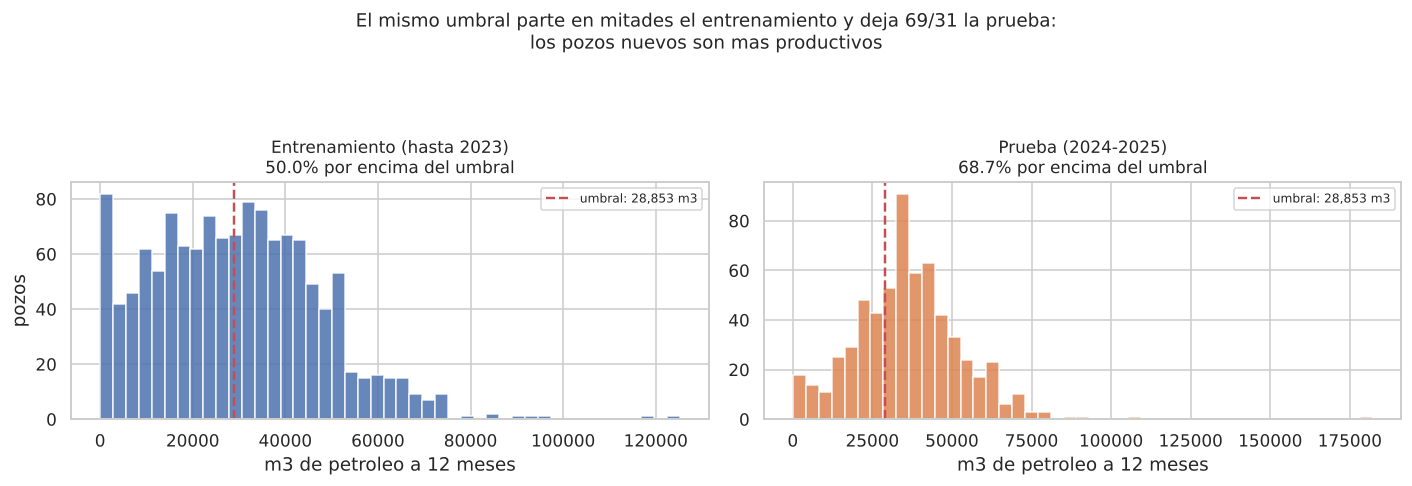

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

for a, (serie, etiqueta, color) in zip(ax, [(y_train, "Entrenamiento (hasta 2023)", "#4C72B0"),
                                            (y_test, "Prueba (2024-2025)", "#DD8452")]):
    a.hist(serie, bins=45, color=color, alpha=0.85)
    a.axvline(UMBRAL, color="#C44E52", ls="--", lw=1.6,
              label=f"umbral: {UMBRAL:,.0f} m3")
    altos = (serie >= UMBRAL).mean()
    a.set_title(f"{etiqueta}\n{altos:.1%} por encima del umbral", fontsize=11)
    a.set_xlabel("m3 de petroleo a 12 meses")
    a.legend(fontsize=8)
ax[0].set_ylabel("pozos")

fig.suptitle("El mismo umbral parte en mitades el entrenamiento y deja 69/31 la prueba:\n"
             "los pozos nuevos son mas productivos", fontsize=12, y=1.10)
plt.tight_layout(); plt.show()

## Una aclaración sobre `stratify`

En clasificación lo habitual es partir con `train_test_split(..., stratify=y)`, para que las dos
mitades conserven la misma proporción de clases. Con una clase rara, un sorteo desafortunado puede
dejarla casi toda de un lado y la evaluación deja de medir lo que importa.

**Acá no lo usamos, y no por descuido: nuestra partición no es aleatoria.** Los pozos se reparten por
año de fractura, y el notebook 02 dedica el punto 8 a justificar por qué. `stratify` es un argumento
de la partición al azar; en una partición temporal no hay sorteo que corregir.

El costo de esa decisión es exactamente el desbalance que acabamos de ver: 50/50 en entrenamiento y
69/31 en prueba. No es un defecto a corregir, es **el fenómeno que queremos medir**. Estratificar
implicaría mezclar años, que es precisamente lo que hace que un modelo parezca el doble de bueno de lo
que es.

# Parte 2: Métricas y modelo de referencia

# 4. Qué métricas usamos y por qué no alcanza con la exactitud

En regresión alcanzaba con MAE, RMSE y R². En clasificación hace falta mirar más de un número, porque
**la exactitud sola puede ser engañosa**, y en este problema lo es: un modelo que diga "alto" siempre
acierta el 68,7% sin haber aprendido nada.

| Métrica | Qué mide | Por qué la miramos |
|---|---|---|
| **Exactitud** | proporción de aciertos | es la intuitiva, pero hay que leerla contra la referencia |
| **Precisión** | de los que predije altos, cuántos lo eran | mide el costo de invertir en un pozo que no rinde |
| **Sensibilidad** | de los altos reales, cuántos detecté | mide el costo de dejar pasar un buen pozo |
| **F1** | media armónica de las dos anteriores | resume el equilibrio entre los dos errores |
| **ROC-AUC** | capacidad de ordenar altos por encima de bajos | **no depende del umbral de decisión** |

El **AUC** es el que más peso tiene en nuestra lectura. Las otras cuatro dependen de dónde se ponga el
corte de probabilidad —por defecto 0,5—, y ese corte es una decisión de negocio, no del modelo. El AUC
mide algo anterior: si el modelo sabe **ordenar** los pozos de peor a mejor. Un AUC de 0,5 es tirar una
moneda; 1,0 es un orden perfecto.

Como referencia usamos el equivalente del "predecir siempre la mediana" del notebook 02: un
`DummyClassifier` que predice la clase mayoritaria de entrenamiento.

In [7]:
def metricas(c_real, c_pred, probabilidad):
    return {"exactitud": accuracy_score(c_real, c_pred),
            "precision": precision_score(c_real, c_pred, zero_division=0),
            "sensibilidad": recall_score(c_real, c_pred, zero_division=0),
            "F1": f1_score(c_real, c_pred, zero_division=0),
            "ROC_AUC": roc_auc_score(c_real, probabilidad)}


pre_lineal = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                      ("escalar", StandardScaler())]), NUMERICAS),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), CATEGORICAS_MODELO)])

pre_arbol = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUMERICAS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS_MODELO)])

resultados = {}


def evaluar(nombre, modelo, pre):
    """Entrena, mide en train y en test, y guarda todo en un unico lugar."""
    p = Pipeline([("pre", pre), ("mod", modelo)]).fit(X_train, c_train)
    prob = p.predict_proba(X_test)[:, 1]
    m = metricas(c_test, p.predict(X_test), prob)
    m["exactitud_train"] = accuracy_score(c_train, p.predict(X_train))
    resultados[nombre] = m
    print(f"{nombre:28s} exactitud {m['exactitud']:.3f}   F1 {m['F1']:.3f}   "
          f"AUC {m['ROC_AUC']:.3f}")
    return p


# Las dos varas: la referencia entrenada y la que surge de conocer el test.
print(f"Prediciendo siempre 'alto' en test se acierta {c_test.mean():.1%}")
print(f"Prediciendo siempre 'bajo' en test se acierta {1 - c_test.mean():.1%}\n")
m_ref = evaluar("Referencia: clase mayoritaria", DummyClassifier(strategy="most_frequent"),
                pre_arbol)

Prediciendo siempre 'alto' en test se acierta 68.7%
Prediciendo siempre 'bajo' en test se acierta 31.3%

Referencia: clase mayoritaria exactitud 0.313   F1 0.000   AUC 0.500


La referencia da una exactitud de **0,313**, y el número merece una explicación porque es
contraintuitivo.

El `DummyClassifier` aprende la clase mayoritaria **de entrenamiento**, pero entrenamiento está
empatado 649 a 649. Ante el empate, scikit-learn se queda con la primera clase: predice **"bajo" para
todos**. Y como en test el 68,7% son altos, acierta solo el 31,3%.

Es el mismo fenómeno que el R² negativo de la referencia en el notebook 02, con otro ropaje: **una
regla aprendida del pasado aplicada a una población que se corrió**. No es un artefacto del
`DummyClassifier`; es información sobre el problema.

Para no quedarnos con una vara artificialmente baja, de acá en adelante comparamos contra el **68,7%**
de "predecir alto siempre". Es más exigente, y es lo que haría alguien que mirara la distribución de
los pozos recientes.

# Parte 3: Entrenamiento y comparación

# 5. Los dos modelos

Entrenamos las mismas dos familias que en regresión, para que la comparación entre los dos notebooks
sea legítima:

- **Regresión logística**, el equivalente lineal: modela la probabilidad de ser alto como una
  combinación de las variables, pasada por una función logística. Es interpretable y es el punto de
  partida obligado.
- **Random Forest**, el equivalente de árboles: captura no linealidades e interacciones sin que las
  declaremos.

Los hiperparámetros del bosque arrancan en los mismos valores que el notebook 02 —`min_samples_leaf=8`,
`max_features=0,4`— y los optimizamos en el punto 7.

In [8]:
m_log = evaluar("Regresion logistica",
                LogisticRegression(max_iter=2000, random_state=SEMILLA), pre_lineal)

m_rf = evaluar("Random Forest",
               RandomForestClassifier(n_estimators=600, min_samples_leaf=8, max_features=0.4,
                                      random_state=SEMILLA, n_jobs=-1), pre_arbol)

Regresion logistica          exactitud 0.735   F1 0.828   AUC 0.742


Random Forest                exactitud 0.750   F1 0.831   AUC 0.744


In [9]:
tabla = pd.DataFrame(resultados).T[["exactitud_train", "exactitud", "precision",
                                    "sensibilidad", "F1", "ROC_AUC"]]
tabla["brecha_exactitud"] = tabla.exactitud_train - tabla.exactitud
print(tabla.to_string(float_format=f3))

                               exactitud_train  exactitud  precision  sensibilidad    F1  ROC_AUC  brecha_exactitud
Referencia: clase mayoritaria            0.500      0.313      0.000         0.000 0.000    0.500             0.187
Regresion logistica                      0.805      0.735      0.747         0.929 0.828    0.742             0.070
Random Forest                            0.892      0.750      0.773         0.899 0.831    0.744             0.143


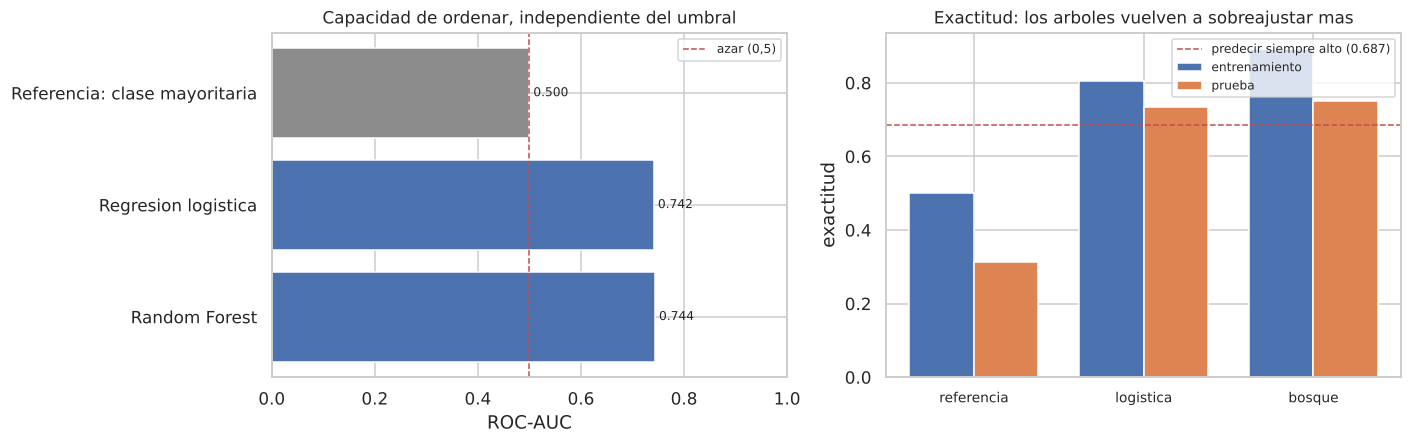

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))

orden = tabla.index.tolist()
colores = ["#8C8C8C"] + ["#4C72B0"] * (len(orden) - 1)

ax[0].barh(orden[::-1], tabla.ROC_AUC[::-1], color=colores[::-1])
ax[0].axvline(0.5, color="#C44E52", ls="--", lw=1, label="azar (0,5)")
ax[0].set_xlabel("ROC-AUC"); ax[0].set_xlim(0, 1)
ax[0].set_title("Capacidad de ordenar, independiente del umbral", fontsize=11)
ax[0].legend(fontsize=8)
for i, v in enumerate(tabla.ROC_AUC[::-1]):
    ax[0].text(v, i, f" {v:.3f}", va="center", fontsize=8)

x = np.arange(len(tabla)); ancho = 0.38
ax[1].bar(x - ancho / 2, tabla.exactitud_train, ancho, label="entrenamiento", color="#4C72B0")
ax[1].bar(x + ancho / 2, tabla.exactitud, ancho, label="prueba", color="#DD8452")
ax[1].axhline(c_test.mean(), color="#C44E52", ls="--", lw=1,
              label=f"predecir siempre alto ({c_test.mean():.3f})")
ax[1].set_xticks(x); ax[1].set_xticklabels(["referencia", "logistica", "bosque"], fontsize=9)
ax[1].set_ylabel("exactitud")
ax[1].set_title("Exactitud: los arboles vuelven a sobreajustar mas", fontsize=11)
ax[1].legend(fontsize=8)

plt.tight_layout(); plt.show()

## Lectura

**Los dos modelos le ganan a las dos referencias.** Random Forest acierta el **75,0%** y la logística
el **73,5%**, contra el 68,7% de predecir "alto" siempre y el 31,3% de la referencia entrenada. La
mejora sobre la vara exigente es de unos 6 puntos.

**El AUC dice que el modelo ordena bastante mejor que el azar**: 0,744 el bosque y 0,742 la logística,
contra 0,5 de tirar una moneda. Dicho de otro modo: si se toman un pozo alto y uno bajo al azar, el
modelo le da mayor probabilidad al alto **tres de cada cuatro veces**.

**Las dos familias empatan**, igual que en regresión. La diferencia de AUC es de 0,002, y la de
exactitud de 1,5 puntos sobre 619 pozos. Vuelve a aparecer la misma conclusión del notebook 02: la
señal que hay en las variables de diseño es mayormente lineal, y los árboles no encuentran
interacciones escondidas que la logística no capture.

**Y los árboles vuelven a sobreajustar más.** El bosque tiene 0,892 de exactitud en entrenamiento
contra 0,750 en prueba —una brecha de 0,143—, mientras la logística va de 0,805 a 0,735, con una
brecha de 0,070: la mitad. Es exactamente el patrón del punto 17 del notebook 02.

**Una asimetría que importa:** la sensibilidad es alta (0,899 en el bosque) y la precisión más baja
(0,773). El modelo detecta casi todos los pozos buenos, pero a costa de marcar como buenos a varios que
no lo son. En el punto 8 lo miramos en la matriz de confusión, que es donde se ve de dónde viene.

# Parte 4: Validación y optimización de hiperparámetros

# 6. Validación cruzada con `TimeSeriesSplit`

Antes de optimizar nada hay que fijar **contra qué** se optimiza. Vale el mismo argumento del punto 15
del notebook 02: `KFold` reparte las filas al azar y le deja ver al modelo pozos del mismo período con
el que después se lo evalúa, que no es la situación real. Usamos `TimeSeriesSplit` sobre los pozos de
entrenamiento ordenados por año de fractura.

La métrica de validación es el **AUC**, no la exactitud, por dos razones: no depende del umbral de
decisión, y no se deja engañar por el desbalance de clases que aparece en cada fold.

In [11]:
# TimeSeriesSplit parte por POSICION de fila: hay que ordenar por tiempo primero.
orden_temporal = train.sort_values(["anio_fractura", "idpozo"]).index
X_train_ord = train.loc[orden_temporal, NUMERICAS + CATEGORICAS_MODELO]
c_train_ord = train.loc[orden_temporal, "es_alto"]
anios_ord = train.loc[orden_temporal, "anio_fractura"].to_numpy()

N_FOLDS = 5
tscv = TimeSeriesSplit(n_splits=N_FOLDS)

print(f"TimeSeriesSplit({N_FOLDS}) sobre los {len(X_train_ord):,} pozos de entrenamiento:\n")
for i, (idx_tr, idx_val) in enumerate(tscv.split(X_train_ord), 1):
    balance = c_train_ord.iloc[idx_val].mean()
    print(f"  fold {i}:  train n={len(idx_tr):4d} ({anios_ord[idx_tr].min():.0f}-"
          f"{anios_ord[idx_tr].max():.0f})  ->  validacion n={len(idx_val):3d} "
          f"({anios_ord[idx_val].min():.0f}-{anios_ord[idx_val].max():.0f}), "
          f"{balance:.0%} altos")

# La referencia se cruza con EL MISMO esquema y EL MISMO scoring que los modelos:
# si un modelo no le gana al azar en validacion cruzada, no hay modelo.
filas = []
for etiqueta, modelo, pre in [
        ("Referencia: mayoritaria", DummyClassifier(strategy="most_frequent"), pre_arbol),
        ("Referencia: al azar", DummyClassifier(strategy="stratified",
                                                random_state=SEMILLA), pre_arbol),
        ("Regresion logistica", LogisticRegression(max_iter=2000, random_state=SEMILLA), pre_lineal),
        ("Random Forest", RandomForestClassifier(n_estimators=600, min_samples_leaf=8,
                                                 max_features=0.4, random_state=SEMILLA,
                                                 n_jobs=-1), pre_arbol)]:
    p = Pipeline([("pre", pre), ("mod", modelo)])
    aucs = cross_val_score(p, X_train_ord, c_train_ord, cv=tscv, scoring="roc_auc", n_jobs=-1)
    # Las otras dos son diagnostico: la metrica que decide es una sola, el AUC.
    exac = cross_val_score(p, X_train_ord, c_train_ord, cv=tscv, scoring="accuracy", n_jobs=-1)
    f1ma = cross_val_score(p, X_train_ord, c_train_ord, cv=tscv, scoring="f1_macro", n_jobs=-1)
    filas.append({"modelo": etiqueta, "AUC_medio": aucs.mean(), "AUC_desvio": aucs.std(),
                  "exactitud_cv": exac.mean(), "f1_macro_cv": f1ma.mean()})
    print(f"\n  {etiqueta:24s} AUC por fold {np.round(aucs, 3)}")

print()
print(pd.DataFrame(filas).set_index("modelo").to_string(float_format=f3))

TimeSeriesSplit(5) sobre los 1,298 pozos de entrenamiento:

  fold 1:  train n= 218 (2011-2017)  ->  validacion n=216 (2017-2019), 33% altos
  fold 2:  train n= 434 (2011-2019)  ->  validacion n=216 (2019-2021), 63% altos
  fold 3:  train n= 650 (2011-2021)  ->  validacion n=216 (2021-2022), 76% altos
  fold 4:  train n= 866 (2011-2022)  ->  validacion n=216 (2022-2023), 61% altos
  fold 5:  train n=1082 (2011-2023)  ->  validacion n=216 (2023-2023), 61% altos



  Referencia: mayoritaria  AUC por fold [0.5 0.5 0.5 0.5 0.5]



  Referencia: al azar      AUC por fold [0.476 0.53  0.561 0.494 0.49 ]



  Regresion logistica      AUC por fold [0.689 0.804 0.786 0.756 0.797]



  Random Forest            AUC por fold [0.714 0.752 0.758 0.744 0.811]

                         AUC_medio  AUC_desvio  exactitud_cv  f1_macro_cv
modelo                                                                   
Referencia: mayoritaria      0.500       0.000         0.411        0.285
Referencia: al azar          0.510       0.031         0.497        0.446
Regresion logistica          0.767       0.042         0.726        0.637
Random Forest                0.756       0.032         0.703        0.616


**El balance de clases se corre fold a fold**: 33% de altos en el primero, 76% en el tercero, 61% en
el último. Es la deriva temporal otra vez —cada fold valida sobre pozos más nuevos que el anterior, y
los pozos nuevos superan más seguido un umbral calibrado con los viejos—, aunque el movimiento no es
monótono: 2021 y 2022 fueron más productivos que 2023, igual que mostraba la tabla del punto 8 del
notebook 02. Es la razón por la que validamos con AUC
y no con exactitud: con clases que se mueven tanto entre folds, promediar exactitudes compara cosas
distintas.

**Los dos modelos le ganan a la referencia dentro de la validación cruzada**, que es la comprobación
que hay que hacer antes de mirar el test: AUC 0,756 y 0,767 contra **0,500 de la referencia
mayoritaria y 0,510 de la que sortea**. Un AUC de 0,5 es exactamente lo que da no saber nada, y es lo
que corresponde: una referencia que predice siempre lo mismo no ordena nada.

La exactitud de validación cruzada deja ver por qué el AUC es la métrica que elegimos para decidir: la
referencia mayoritaria saca 0,411 con un desvío de 0,139, que se mueve según cuántos altos tenga el
fold que toque. El AUC de esa misma referencia es 0,500 en todos los folds, con desvío cero. Una
métrica que no se mueve con el balance de clases es la que sirve para comparar cuando el balance se
mueve.

**Entre los dos modelos no hay ganador.** En validación cruzada la logística saca 0,767 contra 0,756
del bosque; en test el orden se invierte (0,742 contra 0,744). Las diferencias son de milésimas y
caen dentro de los desvíos de 0,042 y 0,032, así que no declaramos ganador: es el mismo empate entre
familias que encontramos en regresión.

# 7. Optimización de hiperparámetros con `GridSearchCV`

La consigna pide **evitar el sobreajuste optimizando los hiperparámetros**, y el bosque es el modelo
que lo necesita: su brecha entre entrenamiento y prueba es de 0,143.

Recorremos la misma grilla que en el punto 16 del notebook 02 —los cuatro parámetros que controlan la
capacidad del bosque—, con la misma validación temporal y maximizando AUC. Son **120 combinaciones ×
5 folds = 600 ajustes**.

In [12]:
grilla = {"mod__n_estimators": [300, 600],
          "mod__min_samples_leaf": [2, 4, 8, 16, 32],
          "mod__max_features": [0.3, 0.4, 0.6, 1.0],
          "mod__max_depth": [None, 8, 14]}

pipe_busqueda = Pipeline([("pre", pre_arbol),
                          ("mod", RandomForestClassifier(random_state=SEMILLA, n_jobs=1))])

busqueda = GridSearchCV(pipe_busqueda, grilla, cv=TimeSeriesSplit(n_splits=N_FOLDS),
                        scoring="roc_auc", n_jobs=-1, refit=True)
busqueda.fit(X_train_ord, c_train_ord)

A_MANO = {"mod__n_estimators": 600, "mod__min_samples_leaf": 8,
          "mod__max_features": 0.4, "mod__max_depth": None}
res_cv = pd.DataFrame(busqueda.cv_results_)
i_mano = next(i for i, p in enumerate(busqueda.cv_results_["params"])
              if all(p[k] == v for k, v in A_MANO.items()))

print(f"Combinaciones evaluadas: {len(res_cv)}  ({len(res_cv) * N_FOLDS} ajustes)\n")
print("Mejor combinacion segun la validacion temporal:")
for k, v in busqueda.best_params_.items():
    print(f"  {k.replace('mod__', ''):20s} {v}")
print(f"\nAUC de validacion cruzada:")
print(f"  mejor de la grilla        {busqueda.best_score_:.4f}")
print(f"  valores elegidos a mano   {res_cv.mean_test_score.iloc[i_mano]:.4f}   "
      f"(puesto {int(res_cv.rank_test_score.iloc[i_mano])} de {len(res_cv)})")

Combinaciones evaluadas: 120  (600 ajustes)

Mejor combinacion segun la validacion temporal:
  max_depth            8
  max_features         0.3
  min_samples_leaf     2
  n_estimators         600

AUC de validacion cruzada:
  mejor de la grilla        0.7754
  valores elegidos a mano   0.7558   (puesto 59 de 120)


In [13]:
# La pregunta de siempre: la mejora de la grilla, ¿se traslada al test?
# Se reentrena en el orden original de las filas, como el resto del notebook.
comparacion = {}
for etiqueta, estimador in [
        ("a mano (el del punto 5)", Pipeline([("pre", pre_arbol), ("mod", RandomForestClassifier(
            n_estimators=600, min_samples_leaf=8, max_features=0.4,
            random_state=SEMILLA, n_jobs=-1))])),
        ("optimizado por GridSearchCV", clone(busqueda.best_estimator_))]:
    e = clone(estimador).fit(X_train, c_train)
    prob = e.predict_proba(X_test)[:, 1]
    m = metricas(c_test, e.predict(X_test), prob)
    m["brecha_exactitud"] = accuracy_score(c_train, e.predict(X_train)) - m["exactitud"]
    comparacion[etiqueta] = m

print(pd.DataFrame(comparacion).T[["exactitud", "F1", "ROC_AUC",
                                   "brecha_exactitud"]].to_string(float_format=f3))

                             exactitud    F1  ROC_AUC  brecha_exactitud
a mano (el del punto 5)          0.750 0.831    0.744             0.143
optimizado por GridSearchCV      0.767 0.846    0.735             0.142


## Lectura: la optimización mejora lo que mide, y se lleva por delante lo que no

El resultado repite el del notebook 02, pero acá es más instructivo porque **se ve el costo**.

En validación cruzada la grilla gana: AUC **0,775** contra **0,756** de los valores a mano, que quedaron
en el puesto 59 de 120. En test, el modelo optimizado **sube la exactitud** de 0,750 a 0,767 y el F1 de
0,831 a 0,846, pero **baja el AUC** de 0,744 a 0,735.

Es decir: mejora las métricas que dependen del umbral y empeora la única que no depende de él. Y lo
hace eligiendo `min_samples_leaf=2` —hojas de dos pozos—, que es *más* capacidad de memorizar, no menos,
en un modelo cuya brecha ya era 0,143.

**Decisión: nos quedamos con el bosque ajustado a mano.** El criterio es el mismo que aplicamos en
regresión: una mejora que aparece en la métrica por la que se optimizó y se evapora en la que mide la
capacidad de ordenar no es una mejora del modelo, es un ajuste a los folds de validación. Lo dejamos
medido y documentado, que es lo que la consigna pide, y no lo adoptamos.

# Parte 5: Diagnóstico del clasificador

# 8. Matriz de confusión y curva ROC

La exactitud dice cuántas veces acierta. La matriz de confusión dice **en qué se equivoca**, que es lo
que define si el modelo sirve para algo.

In [14]:
prob_rf = m_rf.predict_proba(X_test)[:, 1]
pred_rf = m_rf.predict(X_test)
cm = confusion_matrix(c_test, pred_rf)

print("Matriz de confusion, Random Forest:\n")
print(pd.DataFrame(cm, index=["real bajo", "real alto"],
                   columns=["predicho bajo", "predicho alto"]).to_string())
print(f"\nFalsos altos (predije alto, era bajo):  {cm[0, 1]:3d}")
print(f"Falsos bajos (predije bajo, era alto):  {cm[1, 0]:3d}")
print()
print(classification_report(c_test, pred_rf, target_names=["bajo", "alto"], zero_division=0))

Matriz de confusion, Random Forest:

           predicho bajo  predicho alto
real bajo             82            112
real alto             43            382

Falsos altos (predije alto, era bajo):  112
Falsos bajos (predije bajo, era alto):   43

              precision    recall  f1-score   support

        bajo       0.66      0.42      0.51       194
        alto       0.77      0.90      0.83       425

    accuracy                           0.75       619
   macro avg       0.71      0.66      0.67       619
weighted avg       0.74      0.75      0.73       619



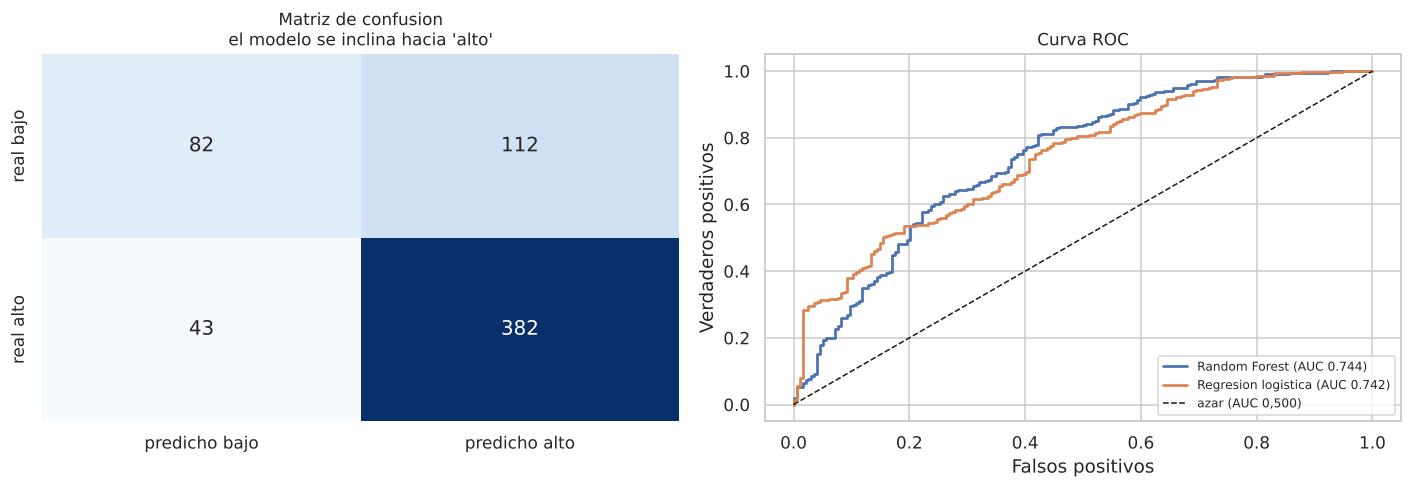

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax[0],
            xticklabels=["predicho bajo", "predicho alto"],
            yticklabels=["real bajo", "real alto"], annot_kws={"size": 13})
ax[0].set_title("Matriz de confusion\nel modelo se inclina hacia 'alto'", fontsize=11)

for etiqueta, prob, color in [("Random Forest", prob_rf, "#4C72B0"),
                              ("Regresion logistica", m_log.predict_proba(X_test)[:, 1], "#DD8452")]:
    fpr, tpr, _ = roc_curve(c_test, prob)
    ax[1].plot(fpr, tpr, color=color, lw=1.8,
               label=f"{etiqueta} (AUC {roc_auc_score(c_test, prob):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", lw=1, label="azar (AUC 0,500)")
ax[1].set_xlabel("Falsos positivos"); ax[1].set_ylabel("Verdaderos positivos")
ax[1].set_title("Curva ROC", fontsize=11); ax[1].legend(fontsize=8, loc="lower right")

plt.tight_layout(); plt.show()

## El modelo es mucho mejor detectando buenos que malos

| | Precisión | Sensibilidad | Pozos |
|---|---|---|---|
| **bajo** | 0,66 | **0,42** | 194 |
| **alto** | 0,77 | **0,90** | 425 |

De los 425 pozos buenos reales detecta **382**, el 90%. De los 194 malos detecta **82**, el 42%: menos
de la mitad. Comete **112 falsos altos** contra **43 falsos bajos**, casi tres veces más.

El modelo está sesgado hacia "alto", y la causa es la misma que explica todo lo demás: aprendió con
pozos cuya mediana es 28.853 m³ y lo aplicamos a pozos que producen más. Es el mismo sesgo del punto
21 del notebook 02, donde el regresor sobreestimaba un 5,8%, visto ahora como falsos positivos.

**Qué significa para usarlo.** Si la pregunta es *"¿me puedo perder un pozo bueno?"*, el modelo sirve:
se le escapa uno de cada diez. Si la pregunta es *"¿puedo confiar en que los que marca como malos son
malos?"*, no sirve: de cada diez que marca como bajos, casi cuatro eran buenos. Para un uso real
convendría **mover el umbral de decisión** por encima de 0,5, que es lo que la curva ROC permite elegir
sin reentrenar nada.

# 9. Qué variables usa el clasificador

Medimos la importancia por permutación sobre el conjunto de prueba, igual que en el punto 20 del
notebook 02, pero con el AUC como métrica: cuánto se degrada la capacidad de ordenar al romper cada
variable.

In [16]:
imp = permutation_importance(m_rf, X_test, c_test, n_repeats=30, random_state=SEMILLA,
                             scoring="roc_auc", n_jobs=-1)
importancia = pd.DataFrame({
    "variable": NUMERICAS + CATEGORICAS_MODELO,
    "caida_AUC": imp.importances_mean,
    "desvio": imp.importances_std}).sort_values("caida_AUC", ascending=False)
print(importancia.to_string(index=False, float_format=lambda x: f"{x:,.4f}"))

                    variable  caida_AUC  desvio
                   operadora     0.1049  0.0163
  longitud_rama_horizontal_m     0.0361  0.0070
      duracion_fractura_dias     0.0325  0.0068
             arena_por_metro     0.0256  0.0050
      espaciamiento_etapas_m     0.0121  0.0034
              agua_por_metro     0.0117  0.0020
            ratio_agua_arena     0.0096  0.0058
          presion_maxima_psi     0.0081  0.0050
potencia_equipos_fractura_hp     0.0049  0.0058
       ratio_arena_importada     0.0000  0.0000


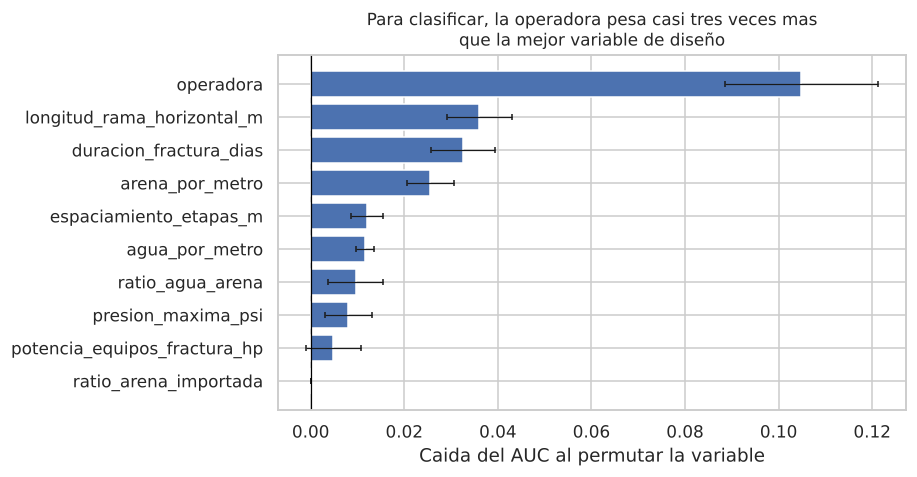

In [17]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
d = importancia.iloc[::-1]
ax.barh(d.variable, d.caida_AUC, xerr=d.desvio, color="#4C72B0",
        error_kw=dict(lw=0.8, capsize=2))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Caida del AUC al permutar la variable")
ax.set_title("Para clasificar, la operadora pesa casi tres veces mas\nque la mejor variable de diseño",
             fontsize=11)
plt.tight_layout(); plt.show()

## La operadora se vuelve dominante

En regresión, `longitud_rama_horizontal_m` y `operadora` **empataban** (+1.629 y +1.594 m³ de error al
permutarlas). Acá no: la operadora hace caer el AUC **0,105** y la rama **0,036**, casi tres veces
menos.

La lectura es que para **ordenar pozos por calidad** —que es lo que mide el AUC— saber quién opera
importa más que saber cuán largo es el tramo horizontal. Tiene sentido con lo que ya sabemos: la
operadora es un *proxy* de la calidad del área en concesión, y la calidad de la roca es justamente lo
que separa un pozo bueno de uno malo. La longitud de rama explica **cuánto** produce un pozo; la
geología explica **si** va a ser bueno.

Dos cambios más respecto de la regresión:

- **`duracion_fractura_dias` sube al tercer puesto** (0,0325), cuando en regresión era sexta y marginal.
  Una operación que se estira es señal de que algo no salió bien, y eso discrimina mejor entre bueno y
  malo que lo que aporta al volumen exacto.
- **`ratio_arena_importada` queda en 0,0000 exacto**, con desvío cero: el modelo no la usa en absoluto.
  En regresión ya era la penúltima (+0,2 m³). Es la candidata más clara a salir del set de variables.

Vale la insistencia de siempre: la operadora **no es causal**. No es que cambiar de empresa mejore el
pozo. Es que cada operadora trabaja en áreas de calidad distinta, y el modelo está leyendo la geología
a través del nombre de la empresa.

# Parte 6: Clasificar contra regresionar

# 10. ¿Conviene entrenar un clasificador o cortar la predicción del regresor?

Esta es la pregunta que hace que valga la pena tener los dos notebooks, y la respuesta no es la que
esperábamos.

Hay dos caminos para contestar "¿va a ser un pozo bueno?":

1. **Clasificar directo**: binarizar el objetivo y entrenar un clasificador. Es lo que hicimos acá.
2. **Regresionar y cortar**: predecir los metros cúbicos con el modelo del notebook 02 y después
   comparar la predicción contra el umbral.

El segundo parece un rodeo. Pero tiene una ventaja que no se ve de entrada: **el regresor aprende con
más información**. Al clasificador le da lo mismo un pozo de 100 m³ que uno de 28.000 —los dos son
"bajo"—, mientras que el regresor usa esa diferencia para aprender. Binarizar antes de entrenar
**tira** esa información.

Lo medimos sobre exactamente la misma pregunta, los mismos pozos y el mismo umbral.

In [18]:
# El regresor del notebook 02, sin cambiarle nada.
m_reg = Pipeline([("pre", pre_arbol),
                  ("mod", RandomForestRegressor(n_estimators=600, min_samples_leaf=8,
                                                max_features=0.4, random_state=SEMILLA,
                                                n_jobs=-1))]).fit(X_train, y_train)
pred_m3 = m_reg.predict(X_test)

# Se corta la prediccion continua en el mismo umbral y se mide como clasificador.
pred_reg_clase = (pred_m3 >= UMBRAL).astype(int)

duelo = pd.DataFrame({
    "clasificador directo": metricas(c_test, pred_rf, prob_rf),
    "regresor discretizado": metricas(c_test, pred_reg_clase, pred_m3),
}).T
print(duelo.to_string(float_format=f3))
print(f"\nDiferencia de AUC a favor del regresor: "
      f"{duelo.loc['regresor discretizado', 'ROC_AUC'] - duelo.loc['clasificador directo', 'ROC_AUC']:+.3f}")

                       exactitud  precision  sensibilidad    F1  ROC_AUC
clasificador directo       0.750      0.773         0.899 0.831    0.744
regresor discretizado      0.763      0.767         0.939 0.844    0.791

Diferencia de AUC a favor del regresor: +0.047


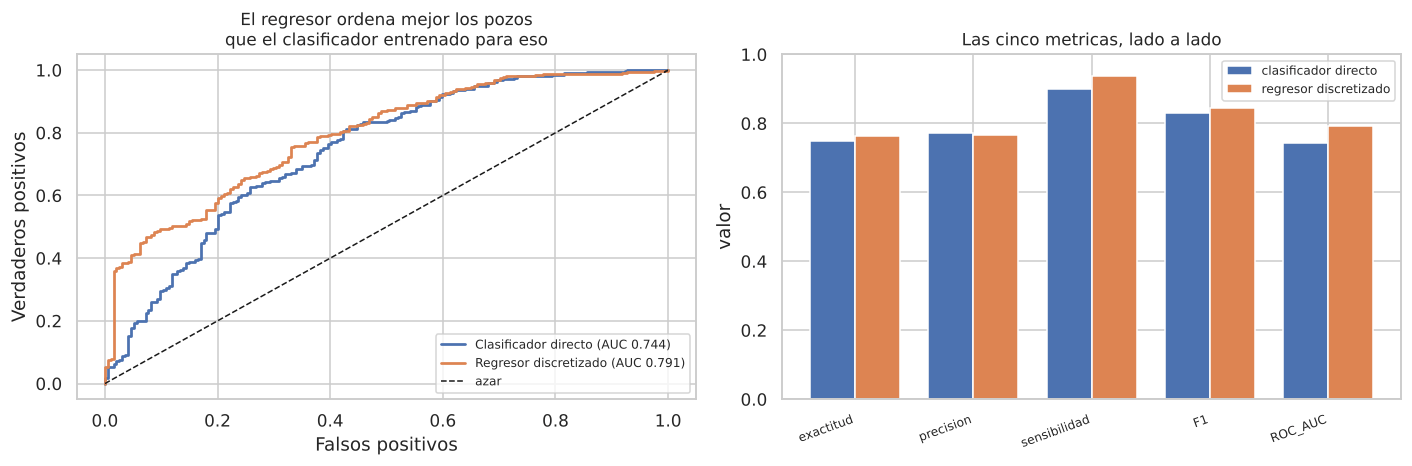

In [19]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))

for etiqueta, puntaje, color in [("Clasificador directo", prob_rf, "#4C72B0"),
                                 ("Regresor discretizado", pred_m3, "#DD8452")]:
    fpr, tpr, _ = roc_curve(c_test, puntaje)
    ax[0].plot(fpr, tpr, color=color, lw=1.8,
               label=f"{etiqueta} (AUC {roc_auc_score(c_test, puntaje):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="azar")
ax[0].set_xlabel("Falsos positivos"); ax[0].set_ylabel("Verdaderos positivos")
ax[0].set_title("El regresor ordena mejor los pozos\nque el clasificador entrenado para eso",
                fontsize=11)
ax[0].legend(fontsize=8, loc="lower right")

met = ["exactitud", "precision", "sensibilidad", "F1", "ROC_AUC"]
x = np.arange(len(met)); ancho = 0.38
ax[1].bar(x - ancho / 2, duelo.loc["clasificador directo", met], ancho,
          label="clasificador directo", color="#4C72B0")
ax[1].bar(x + ancho / 2, duelo.loc["regresor discretizado", met], ancho,
          label="regresor discretizado", color="#DD8452")
ax[1].set_xticks(x); ax[1].set_xticklabels(met, rotation=20, ha="right", fontsize=8)
ax[1].set_ylim(0, 1); ax[1].set_ylabel("valor")
ax[1].set_title("Las cinco metricas, lado a lado", fontsize=11)
ax[1].legend(fontsize=8)

plt.tight_layout(); plt.show()

## El rodeo gana

| Métrica | Clasificador directo | Regresor discretizado |
|---|---|---|
| Exactitud | 0,750 | **0,763** |
| Precisión | **0,773** | 0,767 |
| Sensibilidad | 0,899 | **0,939** |
| F1 | 0,831 | **0,844** |
| **ROC-AUC** | 0,744 | **0,791** |

**El regresor discretizado gana en cuatro de las cinco métricas**, y la diferencia grande está donde
más importa: **+0,047 de AUC**. Para dimensionarlo, es veinte veces la diferencia entre el bosque y la
logística del punto 5, y más que todo lo que movió la optimización de hiperparámetros.

La explicación es la que anticipamos: **el objetivo binario tira información**. Un pozo de 28.000 m³ y
uno de 5.000 son los dos "bajo" para el clasificador, que aprende de los dos lo mismo. El regresor sabe
que uno está al borde y el otro es un fracaso, y esa diferencia le sirve para ordenar mejor. Cuando
después se corta su predicción, ese orden más fino se conserva.

**La conclusión práctica es que para este problema no conviene entrenar un clasificador.** Conviene
usar el regresor y poner el umbral al final, donde además se puede mover según la pregunta de negocio
sin reentrenar nada.

## Por qué esto no es "numerar las etiquetas y meter una recta"

Hay un error clásico que se parece a esto de lejos y es exactamente lo contrario, así que conviene
separarlos con cuidado.

**El error** es tomar una variable categórica, asignarle códigos —digamos `mala=1`, `regular=2`,
`buena=3`— y correr una regresión sobre esos códigos. Está mal por dos razones: los códigos son
arbitrarios, así que el modelo asume que la distancia de 1 a 2 es la misma que de 2 a 3 y que `buena`
está "al doble" de `mala`; y la predicción intermedia no significa nada, porque **un 2,4 no es una
clase**. Las etiquetas no tienen esa geometría.

**Lo que hacemos acá va en la dirección inversa.** No inventamos un número para una categoría: el
número existe primero y la categoría sale de él.

| | Numerar etiquetas | Lo que hacemos |
|---|---|---|
| Qué existe primero | la etiqueta | **el número** (m³ de petróleo, medidos) |
| De dónde sale el otro | se le inventa un código | la etiqueta sale de cortar el número |
| Qué significa un valor intermedio | nada: 2,4 no es una clase | **31.500 m³**, una producción posible y medible |
| La distancia entre valores | inventada | real, en metros cúbicos |

La prueba para distinguirlos es simple: **¿se puede preguntar "cuánto"?** Acá sí —un pozo produce
31.500 m³, y eso es una medición— así que regresionar es legítimo y el umbral es una lectura que se
aplica al final. Si las clases fueran genuinamente categóricas —"el pozo se cerró por falla técnica"
contra "siguió operando"— no habría ningún número que regresionar, y asignarles 1 y 2 sería
exactamente el error de arriba.

Dicho de otra forma: la trampa es **fabricar** una escala donde no la hay. Lo nuestro es **no tirar**
la escala que ya estaba.

# 11. Conclusiones

## Lo que resolvimos

**Clasificar es posible y el modelo aporta.** Con las mismas variables de diseño que usamos para
regresión, el bosque acierta el **75,0%** de los pozos contra el 68,7% de predecir "alto" siempre, con
un AUC de **0,744**: ordena correctamente tres de cada cuatro pares de pozos.

**La optimización de hiperparámetros está hecha y documentada.** 120 combinaciones con `GridSearchCV`
y validación temporal. Sube el AUC de validación cruzada de 0,756 a 0,775, y en test mejora la
exactitud pero **baja el AUC**. No la adoptamos, y explicamos por qué.

## Lo que aprendimos

**Discretizar el objetivo cuesta caro.** Es el resultado central de este notebook: tomar el regresor y
cortar su predicción da **AUC 0,791 contra 0,744** del clasificador entrenado para la tarea. La
diferencia es mayor que la que hay entre modelos o la que produce optimizar hiperparámetros. Cuando la
categoría sale de cortar una variable continua medible, conviene modelar la continua.

**La operadora manda cuando hay que separar buenos de malos.** En regresión empataba con la longitud de
rama; en clasificación pesa casi el triple. La escala del pozo explica **cuánto** produce; la geología
—leída a través de la operadora— explica **si** va a ser bueno.

**El desplazamiento temporal también se ve acá, y de tres formas distintas**: el umbral calibrado con
train deja 69/31 el test, la referencia entrenada cae al 31,3% de exactitud, y el modelo acumula el
triple de falsos altos que de falsos bajos. Es el mismo fenómeno del notebook 02 en tres ropajes
nuevos.

## Limitaciones

| Limitación | Alcance |
|---|---|
| **El umbral es una decisión, no un dato** | con la mediana de train la pregunta es "¿supera lo típico?". Con el cuartil superior sería otro problema y otros números |
| **Sirve para detectar buenos, no para descartar malos** | sensibilidad 0,90 en la clase alta contra 0,42 en la baja |
| **El umbral de decisión quedó en 0,5** | moverlo cambia el balance entre falsos altos y falsos bajos, y para un uso real habría que elegirlo según el costo de cada error |
| **La operadora no es causal** | sigue valiendo lo del notebook 02: no se puede usar para comparar empresas |
| **Validez temporal acotada** | validado sobre 2024-2025. Si el diseño sigue cambiando, el umbral y el modelo se reentrenan |